In [1]:
import Pkg

project_dir = let dir = pwd()
    while !isfile(joinpath(dir, "Project.toml")) && dirname(dir) != dir
        dir = dirname(dir)
    end
    isfile(joinpath(dir, "Project.toml")) || error("No se encontró Project.toml; abre el notebook desde el repositorio.")
    dir
end

Pkg.activate(project_dir)

  Activating project at `c:\Users\Matias\guiado-proyectiles`


# Problema no lineal

Del [modelamiento no lineal](../../docs/modelo_no_lineal.md), tenemos el siguiente problema de Bolza.

$$
\min_{\substack{T>0\\u\in L^\infty([0,T],U)}}
J(u,T):=\int_0^T \frac{\alpha}{2} u^2(t) + \beta \,dt,
$$

sujeto a la dinámica no lineal, la condición inicial $x(0)=x_0$ y la condición terminal

$$
h(x(T))=0,\qquad h(x):=r_x^2+r_y^2-\varepsilon^2,
$$

de modo que la dinámica enstá en una región donde $R>0$ y no aparece la singularidad en $R=0$. 

Para las simulaciones, asumimos sin pérdida de generalidad que la LOS inicial es paralela al eje $x$, pues en caso contrario basta rotar el sistema.

## Simulaciones

In [2]:
using OptimalControl
using NLPModelsIpopt
using Plots


function persecucion_no_lineal(
    t0,
    x0;
    rapidez_M::Real = 5, 
    alpha::Real = 1.0,
    beta::Real = 1.5,
    epsilon::Real = 5e-2,
    max_T::Real = 20,
    max_u::Real = 5,
)
    radio_inicial = hypot(x0[1], x0[2])

    ocp = @def begin
        tf ∈ R, variable
        t ∈ [t0, tf], time
        x = (rx, ry, theta) ∈ R^3, state
        u ∈ R, control

        t0 <= tf <= max_T
        -max_u ≤ u(t) ≤ max_u
        rx(t)^2 + ry(t)^2 >= epsilon^2

        x(t0) == x0
        rx(tf)^2 + ry(tf)^2 == epsilon^2

        ẋ(t) == [
            -rapidez_M * cos(theta(t)),
            -rapidez_M * sin(theta(t)),
            u(t) / rapidez_M * (
                rx(t) * cos(theta(t)) +
                ry(t) * sin(theta(t))
            ) / (sqrt(rx(t)^2 + ry(t)^2) + 1e-4)  # Sumamos un pequeño delta para evitar problemas numéricos
        ]

        ∫(0.5*alpha*u(t)^2 + beta) → min
    end

    return ocp
end


persecucion_no_lineal (generic function with 1 method)

In [3]:
# Datos del problema
pos_target = [60.0, 0.0]
pos_proyectil = [0.0, 0.0]

vel_proyectil = [5.0, 0.0]
rapidez_proyectil = hypot(vel_proyectil[1], vel_proyectil[2])

r0 = pos_target - pos_proyectil
theta0 = atan(vel_proyectil[2], vel_proyectil[1])

t0 = 0.0
x0 = [r0[1], r0[2], theta0]

println("Tiempo inicial: $(t0)")
println("Condición inicial: $(x0)")

desvios_angulares_deg = [-95.0, -90.0, -85.0, -50.0, 0.0, 50.0, 85.0, 90.0, 95.0]

angulos_iniciales = theta0 .+ deg2rad.(desvios_angulares_deg)


Tiempo inicial: 0.0
Condición inicial: [60.0, 0.0, 0.0]


9-element Vector{Float64}:
 -1.6580627893946132
 -1.5707963267948966
 -1.4835298641951802
 -0.8726646259971648
  0.0
  0.8726646259971648
  1.4835298641951802
  1.5707963267948966
  1.6580627893946132

In [4]:
"""
    solucion_alpha_beta(; alpha=1.0, beta=1.5, kwargs...)

Resuelve y grafica las trayectorias para los ángulos iniciales del experimento.
Permite cambiar los pesos del costo, los datos iniciales y los parámetros numéricos.
"""
function solucion_alpha_beta(;
    alpha::Real = 1.0,
    beta::Real = 1.5,
    tiempo_inicial::Real = t0,
    posicion_objetivo::AbstractVector{<:Real} = pos_target,
    posicion_inicial::AbstractVector{<:Real} = pos_proyectil,
    rapidez::Real = rapidez_proyectil,
    angulos::AbstractVector{<:Real} = angulos_iniciales,
    epsilon::Real = 5e-2,
    max_T::Real = 20,
    max_u::Real = 5,
    grid_size::Integer = 50,
    max_iter::Integer = 700,
)
    posicion_relativa = posicion_objetivo - posicion_inicial
    soluciones = map(angulos) do theta_inicial
        estado_inicial = [posicion_relativa[1], posicion_relativa[2], theta_inicial]
        problema = persecucion_no_lineal(
            tiempo_inicial, estado_inicial;
            rapidez_M = rapidez, alpha = alpha, beta = beta,
            epsilon = epsilon, max_T = max_T, max_u = max_u,
        )
        println("Resolviendo para θ₀ = $(round(rad2deg(theta_inicial), digits=1))°, α = $alpha, β = $beta")
        @time solve(problema; grid_size = grid_size, max_iter = max_iter)
    end

    grafico = plot(
        xlabel = "Posición x",
        ylabel = "Posición y",
        title = "Trayectorias del misil (α = $alpha, β = $beta)",
        aspect_ratio = :equal,
    )

    for (theta_inicial, solucion) in zip(angulos, soluciones)
        tiempos = time_grid(solucion)
        estado_relativo = state(solucion)
        trayectoria_x = [posicion_objetivo[1] - estado_relativo(t)[1] for t in tiempos]
        trayectoria_y = [posicion_objetivo[2] - estado_relativo(t)[2] for t in tiempos]
        etiqueta = "θ₀ = $(round(rad2deg(theta_inicial), digits=1))°"
        plot!(grafico, trayectoria_x, trayectoria_y; label = etiqueta, linewidth = 2)
    end

    scatter!(grafico, [posicion_inicial[1]], [posicion_inicial[2]];
        label = "Inicio del misil", marker = :circle, markersize = 6)
    scatter!(grafico, [posicion_objetivo[1]], [posicion_objetivo[2]];
        label = "Objetivo", marker = :circle, markersize = 6)
    return grafico
end


solucion_alpha_beta

Resolviendo para θ₀ = -95.0°, α = 1.0, β = 1.5
▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 50)
   ├─ Modeler: adnlp
   └─ Solver: ipopt (max_iter = 700)

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:      905
Number of nonzeros in inequality constraint Jacobian.:      102
Number of nonzeros in Lagrangian Hessian.............:     1309

Total number of variables............................:      204
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       51
                     variables with only upper bounds:        0
Total number of equality constraints.................:      154
Total number of inequality constraints...............:       51
        inequality constraints with only lower bounds:       51
   inequality constraints with 

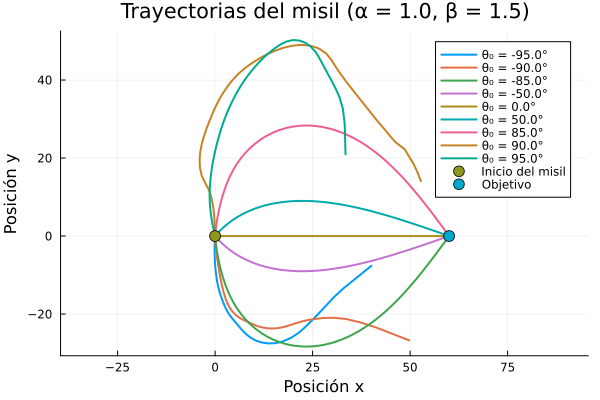

Resolviendo para θ₀ = -95.0°, α = 0.001, β = 1.5
▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 50)
   ├─ Modeler: adnlp
   └─ Solver: ipopt (max_iter = 700)

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:      905
Number of nonzeros in inequality constraint Jacobian.:      102
Number of nonzeros in Lagrangian Hessian.............:     1309

Total number of variables............................:      204
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       51
                     variables with only upper bounds:        0
Total number of equality constraints.................:      154
Total number of inequality constraints...............:       51
        inequality constraints with only lower bounds:       51
   inequality constraints wit

Excessive output truncated after 524295 bytes.

Resolviendo para θ₀ = 90.0°, α = 0.001, β = 1.5
▫ This is OptimalControl 2.0.4, solving with: 

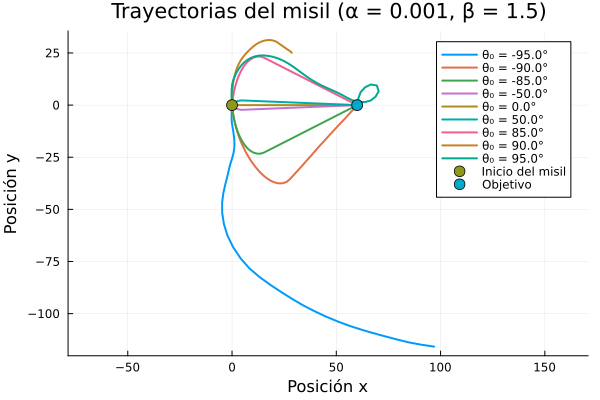

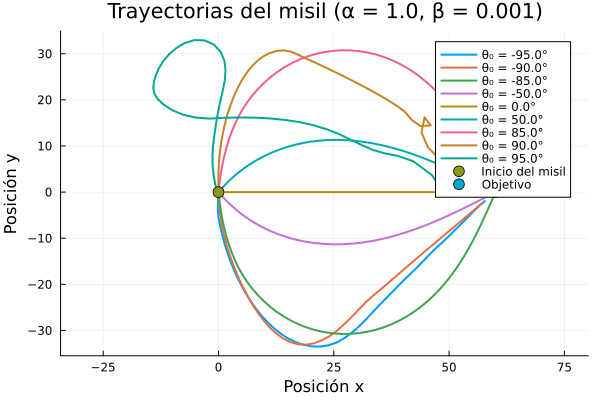

In [ ]:
display(solucion_alpha_beta(; alpha = 1.0, beta = 1.5))
display(solucion_alpha_beta(; alpha = 0.001, beta = 1.5))
display(solucion_alpha_beta(; alpha = 1.0, beta = 0.001))
